In [35]:
import numpy as np
import pandas as pd
import pyxlsb
import seaborn as sns


In [36]:
stctv2 = pd.read_excel("stc TV Data Set_T2.xlsx")

In [37]:
stctv2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Unnamed: 0                  86 non-null     int64         
 1   date_                       86 non-null     datetime64[ns]
 2   Total_watch_time_in_houres  86 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 2.1 KB


In [38]:
stctv2.head()

,Unnamed: 0,date_,Total_watch_time_in_houres
0,0,2018-01-01,1123.551944
1,1,2018-01-02,1000.129722
2,2,2018-01-03,881.924444
3,3,2018-01-04,782.669444
4,4,2018-01-05,1051.939444


In [39]:
stctv2.drop("Unnamed: 0", axis=1, inplace=True)
stctv2.head()

,date_,Total_watch_time_in_houres
0,2018-01-01,1123.551944
1,2018-01-02,1000.129722
2,2018-01-03,881.924444
3,2018-01-04,782.669444
4,2018-01-05,1051.939444


In [40]:
stctv2.describe()

,date_,Total_watch_time_in_houres
count,86,86.000000
mean,2018-02-28 17:01:23.720930304,780.817926
min,2018-01-01 00:00:00,562.124722
25%,2018-01-30 06:00:00,707.709653
50%,2018-02-28 12:00:00,763.181389
75%,2018-03-29 18:00:00,840.985278
max,2018-04-30 00:00:00,1123.551944
std,NaN,122.992002


In [41]:
import matplotlib.pyplot as plt 
import plotly 
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [43]:
figureOne = px.line(stctv2, x="date_", y="Total_watch_time_in_houres")
figureOne.show()

In [45]:
pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [53]:
from prophet import Prophet

In [54]:
stctvPrediction = stctv2[["date_", "Total_watch_time_in_houres"]].copy()
stctvPrediction.columns = ["ds", "y"]

In [55]:
model = Prophet(weekly_seasonality=False)
model.fit(stctvPrediction)

23:08:54 - cmdstanpy - INFO - Chain [1] start processing
23:08:55 - cmdstanpy - INFO - Chain [1] done processing


In [56]:
future = model.make_future_dataframe(periods=61)

In [57]:
prediction = model.predict(future)

C:\Users\Turki\AppData\Local\Temp\ipykernel_4472\4208124844.py:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



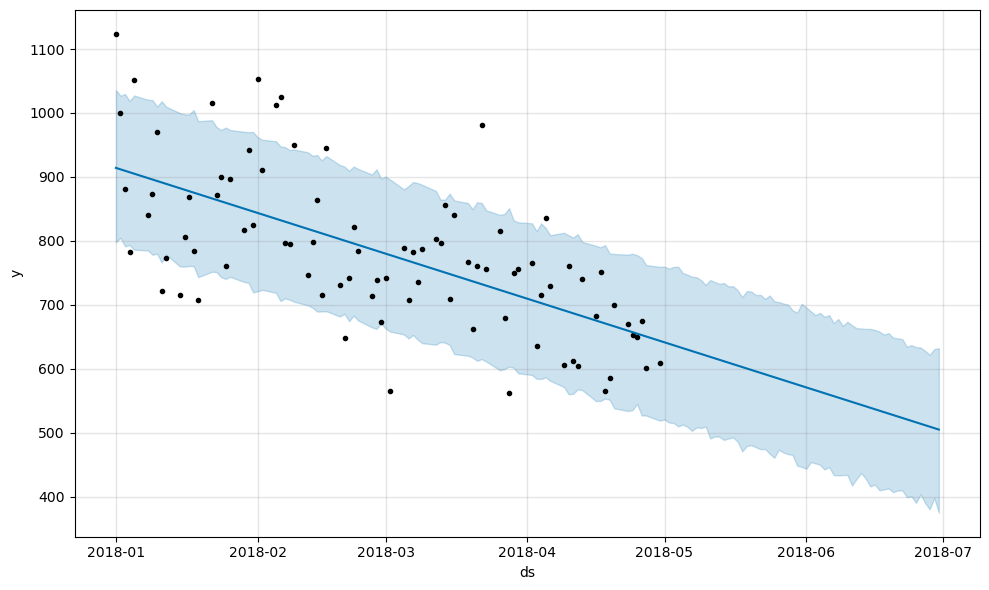

In [58]:
figureTwo = model.plot(prediction)
figureTwo.show()

The prediction shows the trend from Jan–Apr 2018 data. Since the data lacks weekends and spans only 4 months, the model can't detect seasonal patterns like summer break. Real watch hours in May–June are likely higher than shown here, based on the expectation that people watch more TV during summer vacation.